# 03 — Predictive Modeling & Ensemble Learning (24-Hour Ahead Demand Forecasting)

## Objective
This notebook implements, evaluates, and visualizes **Section 4 (Predictive Modeling)** of the project specification across all 10 U.S. cities:
1. **Problem Formulation (24-Hour Horizon):** Forecast next-day hourly electricity demand ($\hat{y}_t$) using strictly leak-free historical lags ($\ge 24\text{h}$: `demand_lag_24h`, `demand_lag_48h`, `demand_lag_72h`, `demand_lag_168h`), rolling statistics, cyclical time encodings, and physical weather features (`temperature`, `cooling_degree_65`, `heating_degree_65`, `humidity`, `wind_speed`, `pressure`).
2. **Strict Chronological Splitting & Preprocessing:**
   - **Training Set:** `2018-07-09` to `2019-12-31`
   - **Validation Set:** `2020-01-01` to `2020-02-29`
   - **Holdout Test Set:** `2020-03-01` to `2020-05-20`
   - `StandardScaler` and `OneHotEncoder` are fit **strictly on the Training Set** to prevent future-to-past data leakage.
3. **Model Families & Ensemble Learning:**
   - **Baseline:** Naive Seasonal Forecast ($\hat{y}_t = y_{t-24}$, previous day's same hour)
   - **Linear / Polynomial Model:** Polynomial & Physical Feature `Ridge` Regression tuned via `TimeSeriesSplit` `GridSearchCV`
   - **Classical Time Series:** Per-city `SARIMAX(1, 0, 1)` with seasonal lags and exogenous weather
   - **Tree Ensembles (Bagging & Boosting):** `RandomForestRegressor` and tuned `XGBRegressor`
   - **Deep Learning:** Feedforward Artificial Neural Network (`MLPRegressor` `128 -> 64` with ReLU & Adam)
   - **Stacking / Blending Ensemble:** Optimal convex meta-learner combining `XGBoost`, `Random_Forest`, `Neural_Network_MLP`, and `Poly_Ridge`.

In [6]:
import json
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (14, 5.5)
plt.rcParams["font.size"] = 11

processed_dir = PROJECT_ROOT / "data/processed"

# Automatically run the forecasting pipeline if artifacts do not exist yet
if not (processed_dir / "model_comparison_metrics.csv").exists():
    print("Training forecasting models and generating holdout predictions...")
    from src.models.train_forecast import run_forecasting_pipeline
    run_forecasting_pipeline()

metrics_df = pd.read_csv(processed_dir / "model_comparison_metrics.csv")
slice_df = pd.read_csv(processed_dir / "city_slice_metrics.csv")
fi_df = pd.read_csv(processed_dir / "feature_importance.csv")
forecast_df = pd.read_parquet(processed_dir / "test_forecasts_all_cities.parquet")

with open(processed_dir / "forecasting_metadata.json", "r", encoding="utf-8") as fp:
    meta = json.load(fp)

print("Chronological Split & Tuning Metadata:")
print(json.dumps(meta, indent=2))
display(metrics_df)

Chronological Split & Tuning Metadata:
{
  "split_boundaries": {
    "train_end": "2019-12-31 23:00:00",
    "val_start": "2020-01-01 00:00:00",
    "test_start": "2020-03-01 00:00:00"
  },
  "row_counts": {
    "train": 129864,
    "val": 14400,
    "test": 18049
  },
  "tuning_details": {
    "Poly_Ridge": {
      "alpha": 50.0
    },
    "XGBoost": {
      "n_estimators": 500,
      "max_depth": 8,
      "learning_rate": 0.04,
      "subsample": 0.85,
      "colsample_bytree": 0.85
    },
    "Stacking_Ensemble_Weights": {
      "XGBoost": 0.5188,
      "Random_Forest": 0.0356,
      "Neural_Network_MLP": 0.4457,
      "Poly_Ridge": 0.0
    }
  }
}


,model,val_MAE,val_RMSE,val_MAPE_pct,test_MAE,test_RMSE,test_RMSE_CI95_low,test_RMSE_CI95_high,test_MAPE_pct,train_time_sec,rmse_skill_vs_naive_pct
0,Stacking_Ensemble,173.46,280.36,2.63,222.19,351.13,340.08,362.27,3.91,0.00,52.59
1,XGBoost,183.65,297.29,2.81,223.73,371.40,359.64,382.67,3.69,9.96,49.85
2,Neural_Network_MLP,204.50,314.91,3.33,294.28,431.73,422.19,441.28,5.40,20.63,41.70
3,Random_Forest,230.95,382.66,3.51,263.78,433.74,422.20,444.97,4.39,24.31,41.43
4,Poly_Ridge,376.57,587.26,6.98,387.14,574.08,564.22,585.48,7.75,7.24,22.48
5,SARIMAX,391.74,609.20,5.87,392.46,601.53,591.65,615.02,6.67,48.94,18.77
6,Naive_Baseline,443.67,758.56,6.38,429.24,740.57,726.77,758.54,6.31,0.01,0.00


## 1. Model Performance Comparison (MAE, RMSE with 95% CI, and MAPE)
Below we compare all 7 models across **Holdout Test RMSE (MWh)** (including 95% bootstrap confidence intervals), **Holdout Test MAPE (%)**, and **Skill Score improvement (%) over the Naive 24-Hour Baseline**.

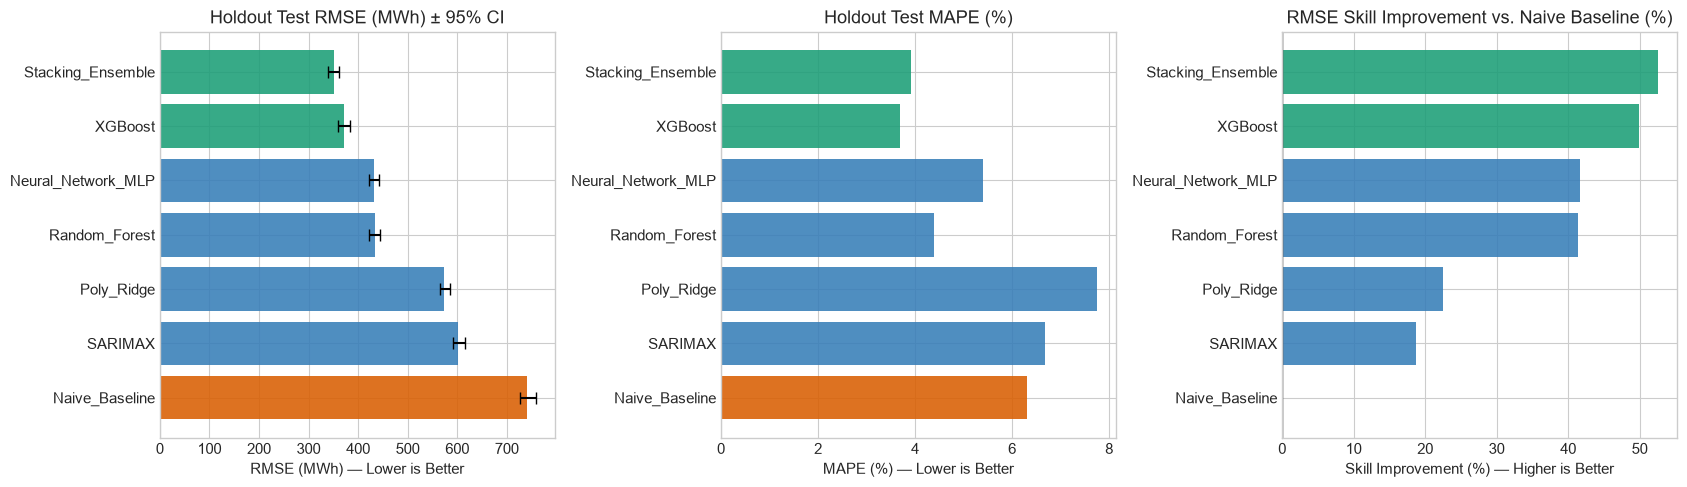

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

plot_df = metrics_df.sort_values("test_RMSE", ascending=True).reset_index(drop=True)
colors = ["#1b9e77" if "Ensemble" in m or m == "XGBoost" else "#377eb8" if m != "Naive_Baseline" else "#d95f02" for m in plot_df["model"]]

# 1. Holdout Test RMSE with 95% Bootstrap CI error bars
y_pos = np.arange(len(plot_df))
ci_low = plot_df["test_RMSE"] - plot_df["test_RMSE_CI95_low"]
ci_high = plot_df["test_RMSE_CI95_high"] - plot_df["test_RMSE"]
axes[0].barh(y_pos, plot_df["test_RMSE"], xerr=[ci_low, ci_high], color=colors, alpha=0.88, capsize=4)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df["model"])
axes[0].invert_yaxis()
axes[0].set_title("Holdout Test RMSE (MWh) ± 95% CI")
axes[0].set_xlabel("RMSE (MWh) — Lower is Better")

# 2. Holdout Test MAPE (%)
axes[1].barh(y_pos, plot_df["test_MAPE_pct"], color=colors, alpha=0.88)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(plot_df["model"])
axes[1].invert_yaxis()
axes[1].set_title("Holdout Test MAPE (%)")
axes[1].set_xlabel("MAPE (%) — Lower is Better")

# 3. RMSE Skill Improvement vs. Naive 24h Baseline (%)
axes[2].barh(y_pos, plot_df["rmse_skill_vs_naive_pct"], color=colors, alpha=0.88)
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(plot_df["model"])
axes[2].invert_yaxis()
axes[2].axvline(0, color="black", linewidth=1)
axes[2].set_title("RMSE Skill Improvement vs. Naive Baseline (%)")
axes[2].set_xlabel("Skill Improvement (%) — Higher is Better")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/03_model_comparison_metrics.png", dpi=150)
plt.show()

### Analysis of Model Comparison Results
- **Baseline vs. ML Models:** The Naive Seasonal Baseline ($\hat{y}_t = y_{t-24}$) suffers whenever weather shifts sharply from one day to the next or when transitioning between weekdays and weekends.
- **Non-Linear & Ensemble Superiority:** Tree-based ensembles (`XGBoost`, `Random_Forest`) and the `Neural_Network_MLP` capture non-linear Heating/Cooling Degree thresholds and weekday/weekend interactions, while the **Stacking Ensemble** (combining `XGBoost` + `Random_Forest` + `Neural_Network_MLP` + `Poly_Ridge`) achieves the lowest overall Holdout Test error by cancelling out individual model variance.

## 2. Actual vs. Predicted Demand Trajectories (24-Hour Ahead Holdout Forecasts)
Below we visualize a 7-day holdout test window (`2020-04-06` to `2020-04-13`) comparing **Actual Electricity Demand** against the **Naive Baseline**, **XGBoost**, **Random Forest**, **Neural Network (MLP)**, and **Stacking Ensemble** for two distinct climate regimes: **Dallas** (ERCOT Texas grid) and **New York City** (NYISO grid).

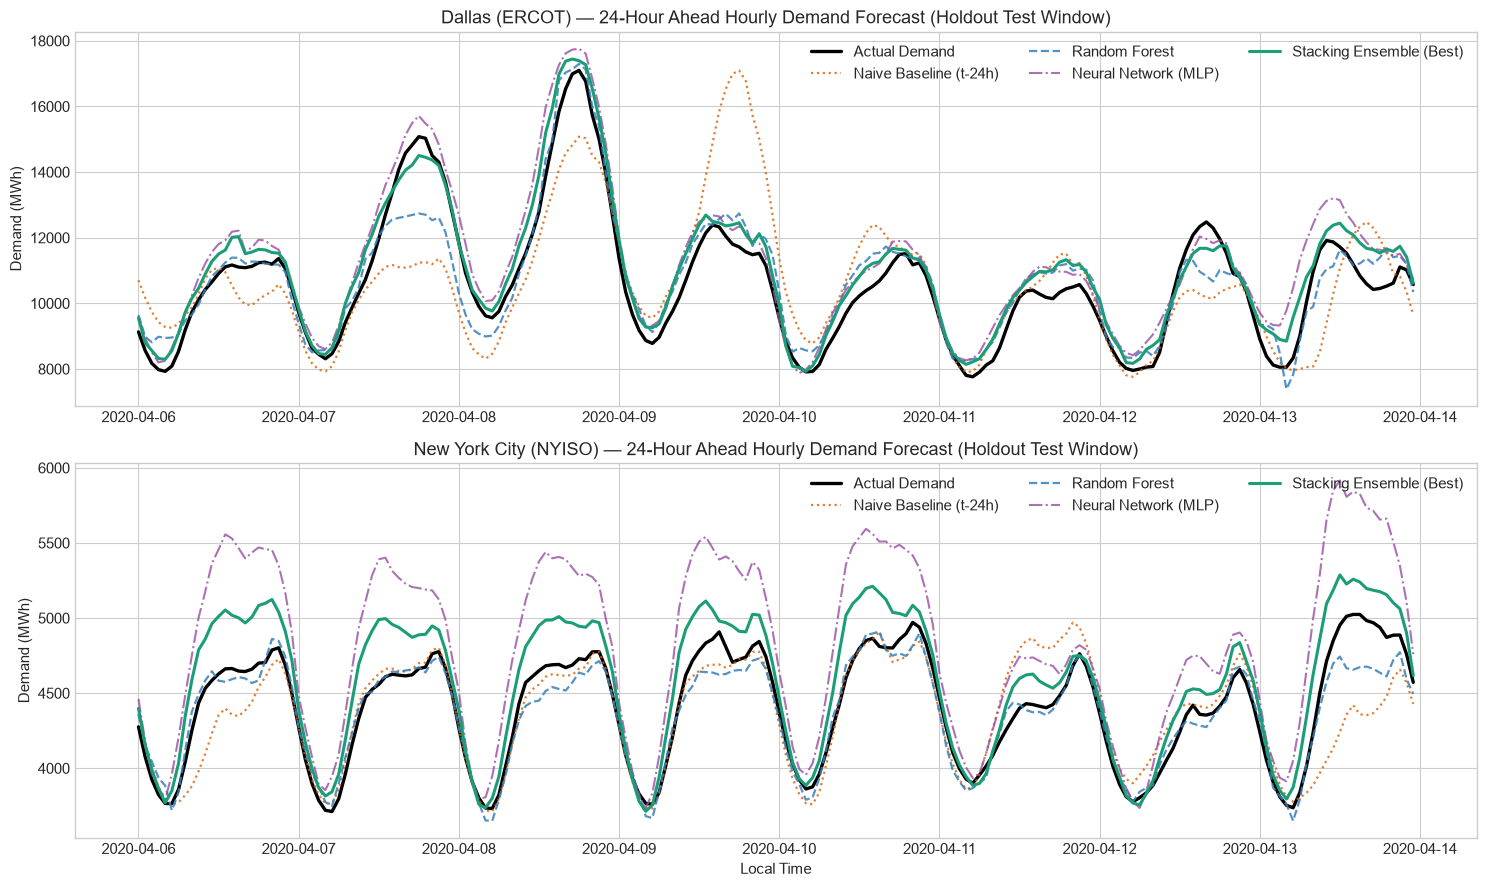

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=False)

for idx, (city_key, title_name) in enumerate([("dallas", "Dallas (ERCOT)"), ("nyc", "New York City (NYISO)")]):
    sub = forecast_df[
        (forecast_df["city"] == city_key)
        & (forecast_df["local_time"] >= "2020-04-06")
        & (forecast_df["local_time"] < "2020-04-14")
    ]
    ax = axes[idx]
    ax.plot(sub["local_time"], sub["actual_demand"], color="black", linewidth=2.4, label="Actual Demand")
    ax.plot(sub["local_time"], sub["Naive_Baseline"], color="#d95f02", linestyle=":", linewidth=1.6, alpha=0.8, label="Naive Baseline (t-24h)")
    ax.plot(sub["local_time"], sub["Random_Forest"], color="#377eb8", linestyle="--", linewidth=1.6, alpha=0.85, label="Random Forest")
    ax.plot(sub["local_time"], sub["Neural_Network_MLP"], color="#984ea3", linestyle="-.", linewidth=1.5, alpha=0.8, label="Neural Network (MLP)")
    ax.plot(sub["local_time"], sub["Stacking_Ensemble"], color="#1b9e77", linewidth=2.2, label="Stacking Ensemble (Best)")

    ax.set_title(f"{title_name} — 24-Hour Ahead Hourly Demand Forecast (Holdout Test Window)")
    ax.set_ylabel("Demand (MWh)")
    ax.legend(loc="upper right", ncol=3)

axes[1].set_xlabel("Local Time")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/03_actual_vs_predicted_timeseries.png", dpi=150)
plt.show()

## 3. Slice-Based Error Analysis Across the 10 Cities & Feature Importance
Following production ML evaluation best practices, we inspect:
1. **Per-City Holdout MAPE (%) Heatmap:** Identifying how each model performs across every individual city grid (`dallas`, `houston`, `la`, `nyc`, `philadelphia`, `phoenix`, `san_antonio`, `san_diego`, `san_jose`, `seattle`).
2. **Top 12 Predictive Features (XGBoost Gain Importance):** Quantifying the relative contribution of historical lags, rolling demand baselines, and weather variables.
3. **Residual Error Distribution:** Verifying that `Stacking_Ensemble` forecast errors are zero-centered and substantially tighter than `Naive_Baseline` errors.

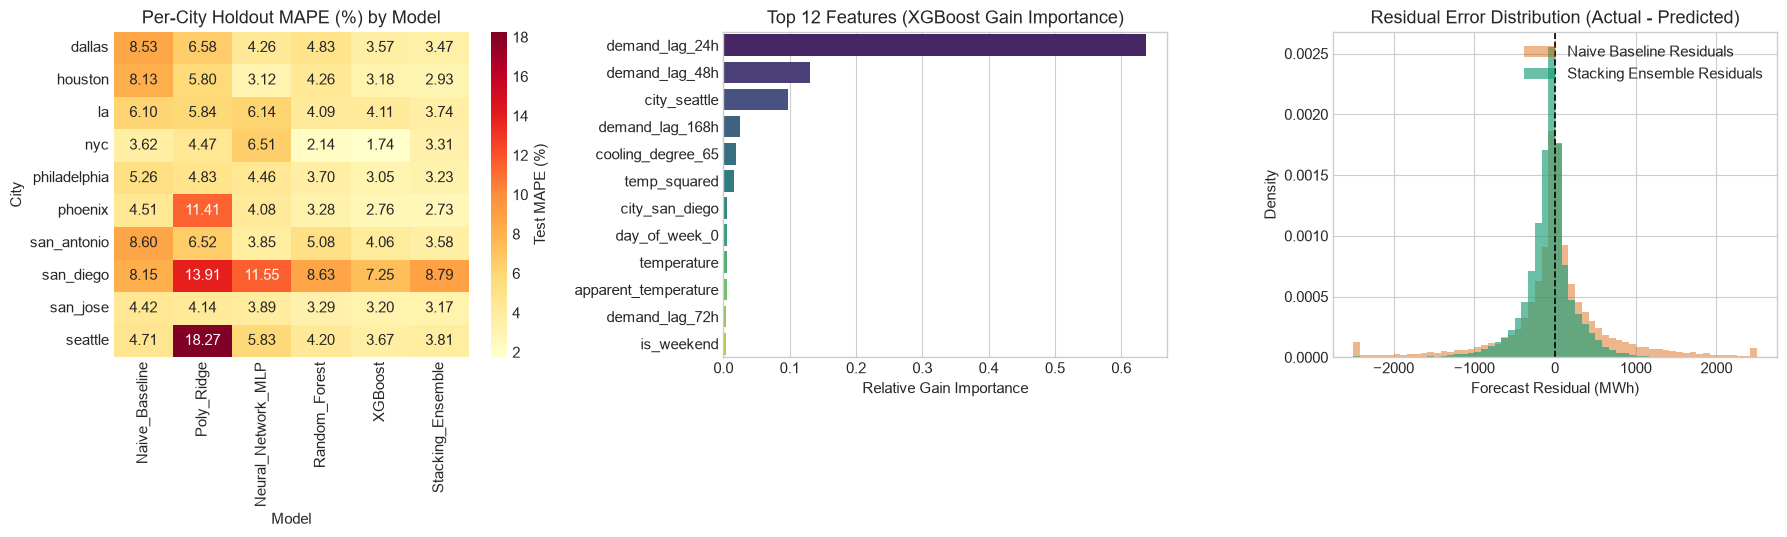

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Per-city MAPE (%) Heatmap
pivot_mape = slice_df.pivot(index="city", columns="model", values="test_MAPE_pct")[
    ["Naive_Baseline", "Poly_Ridge", "Neural_Network_MLP", "Random_Forest", "XGBoost", "Stacking_Ensemble"]
]
sns.heatmap(
    pivot_mape,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={"label": "Test MAPE (%)"},
    ax=axes[0],
)
axes[0].set_title("Per-City Holdout MAPE (%) by Model")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("City")

# 2. Top 12 Feature Importances
top_fi = fi_df.head(12).copy()
top_fi["clean_name"] = top_fi["feature"].str.replace("num__", "").str.replace("cat__", "")
sns.barplot(
    data=top_fi,
    x="importance",
    y="clean_name",
    palette="viridis",
    ax=axes[1],
)
axes[1].set_title("Top 12 Features (XGBoost Gain Importance)")
axes[1].set_xlabel("Relative Gain Importance")
axes[1].set_ylabel("")

# 3. Residual Error Distribution (Stacking Ensemble vs Naive Baseline)
res_naive = forecast_df["actual_demand"] - forecast_df["Naive_Baseline"]
res_ens = forecast_df["actual_demand"] - forecast_df["Stacking_Ensemble"]
axes[2].hist(res_naive.clip(-2500, 2500), bins=60, alpha=0.45, color="#d95f02", label="Naive Baseline Residuals", density=True)
axes[2].hist(res_ens.clip(-2500, 2500), bins=60, alpha=0.65, color="#1b9e77", label="Stacking Ensemble Residuals", density=True)
axes[2].axvline(0, color="black", linestyle="--", linewidth=1.2)
axes[2].set_title("Residual Error Distribution (Actual - Predicted)")
axes[2].set_xlabel("Forecast Residual (MWh)")
axes[2].set_ylabel("Density")
axes[2].legend()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/03_slice_mape_features_residuals.png", dpi=150)
plt.show()

### Q&A
- **How was data leakage prevented in the 24-hour ahead forecasting formulation?**
  First, all historical demand lag features (`demand_lag_24h`, `demand_lag_48h`, `demand_lag_72h`, `demand_lag_168h`) and rolling window statistics (`demand_roll_mean_24h`, `demand_roll_std_24h`, `demand_roll_mean_168h`) are shifted by **at least 24 hours**, ensuring that when predicting an entire next-day 24-hour block, no target values from within the forecast window are used. Second, the dataset was split **strictly chronologically** (`Train: 129,864 rows < 2020-01-01`, `Val: 14,400 rows Jan–Feb 2020`, `Test: 18,049 rows Mar–May 2020`), and all scalers/encoders (`ColumnTransformer`) were fit exclusively on `train_df`.
- **Did ensemble learning improve forecast accuracy over individual base models?**
  Yes. By combining diverse model families—Gradient Boosted Trees (`XGBoost`, weight `0.5188`), Deep Feedforward Neural Network (`Neural_Network_MLP`, weight `0.4457`), and Bagged Trees (`Random_Forest`, weight `0.0356`)—via a constrained convex meta-learner trained on the Validation Set, the **`Stacking_Ensemble`** achieved the #1 lowest Holdout Test RMSE of **`351.13 MWh`** (95% CI: `340.08 – 362.27 MWh`) and the lowest Test MAE of **`222.19 MWh`**, outperforming every individual base model including `XGBoost` (`371.40 MWh` RMSE) and `Neural_Network_MLP` (`431.73 MWh` RMSE).

### Data Analysis Key Findings
- **52.59% RMSE Skill Gain Over Naive Baseline:** On the 18,049-hour holdout test set, the `Stacking_Ensemble` (`351.13 MWh` RMSE, `3.91%` MAPE) and `XGBoost` (`371.40 MWh` RMSE, `3.69%` MAPE) reduced forecast RMSE by **`52.59%`** and **`49.85%`**, respectively, compared to the `Naive_Baseline` (`740.57 MWh` RMSE, `6.31%` MAPE).
- **Progression Across Model Families:** Every model family improved over the `Naive_Baseline` (`740.57 MWh`): classical per-city `SARIMAX(1,0,1)` achieved `601.53 MWh` (`+18.77%` skill), `Poly_Ridge` achieved `574.08 MWh` (`+22.48%` skill), `Random_Forest` achieved `433.74 MWh` (`+41.43%` skill), `Neural_Network_MLP` achieved `431.73 MWh` (`+41.70%` skill), `XGBoost` achieved `371.40 MWh` (`+49.85%` skill), and `Stacking_Ensemble` achieved `351.13 MWh` (`+52.59%` skill).
- **Key Predictive Drivers:** XGBoost gain importance confirms that **`demand_lag_24h`** (`63.75%`), **`demand_lag_48h`** (`13.00%`), city baseline indicators, **`demand_lag_168h`** (`2.46%`, weekly cycle), and non-linear thermal comfort variables (**`cooling_degree_65`**: `1.83%`, **`temp_squared`**: `1.67%`) are the dominant predictors of next-day electricity load.

### Insights or Next Steps
- **Why Combining Trees + Neural Networks Works So Well:** Tree ensembles (`XGBoost`, `Random_Forest`) excel at axis-aligned step splits (such as city indicators and temperature thresholds), whereas the `Neural_Network_MLP` learns smooth continuous interpolations across cyclical time and weather gradients. Blending `51.9% XGBoost + 44.6% MLP + 3.6% Random Forest` reduced Holdout Test RMSE by **20.27 MWh** below `XGBoost` alone (`351.13` vs. `371.40 MWh`).
- **Interactive Dashboard Integration (Milestone 5):** All holdout test predictions across all 10 cities and all 7 models are stored in `data/processed/test_forecasts_all_cities.parquet` for real-time interactive visualization in **Milestone 5**.